# Лабораторная работа №1. Кластеризация методом k-средних и методом DBSCAN.

Выполнила Чуприна Анна.

In [48]:
#  Активируем библиотеки

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
matplotlib.style.use('seaborn-v0_8-whitegrid')
import plotly.express as px
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN
from sklearn import metrics


import seaborn as sns


# Разведочный анализ данных (EDA)

Начнем с того, что прочитаем представленную таблицу.

**Экономика городов.**

1) Данные описывают экономические условия в 48 городах мира в 1991 году.
Данные были собраны отделом экономических исследований банка Union
(Швейцария). Описаны экономические условия в 48 городах мира в 1991 году.

2) Число наблюдений: 48.
3) Названия переменных:

* Сity (Город): Название города.

* Работа (Work): Взвешенное среднее числа рабочих часов, сосчитанное по 12
профессиям.

* Цена (Price): Индекс цен 112 товаров и услуг, включая арендную плату за
жилье (значение для Цюриха взято за 100%).

* Заработная плата (Salary): Индекс заработной платы за час работы,
сосчитанный по 12 профессиям после налогов и вычетов (значение для Цюриха
взято за 100%).

Данные содержатся в файле Economics_of_Cities.сsv

In [4]:
dataset = pd.read_csv('Econom_Cities_data.csv',sep=';',decimal=',')
dataset.head()

,City,Work,Price,Salary
0,Amsterdam,1714,65.6,49.0
1,Athens,1792,53.8,30.4
2,Bogota,2152,37.9,11.5
3,Bombay,2052,30.3,5.3
4,Brussels,1708,73.8,50.5


In [5]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   City    48 non-null     object 
 1   Work    48 non-null     int64  
 2   Price   48 non-null     float64
 3   Salary  48 non-null     float64
dtypes: float64(2), int64(1), object(1)
memory usage: 1.6+ KB


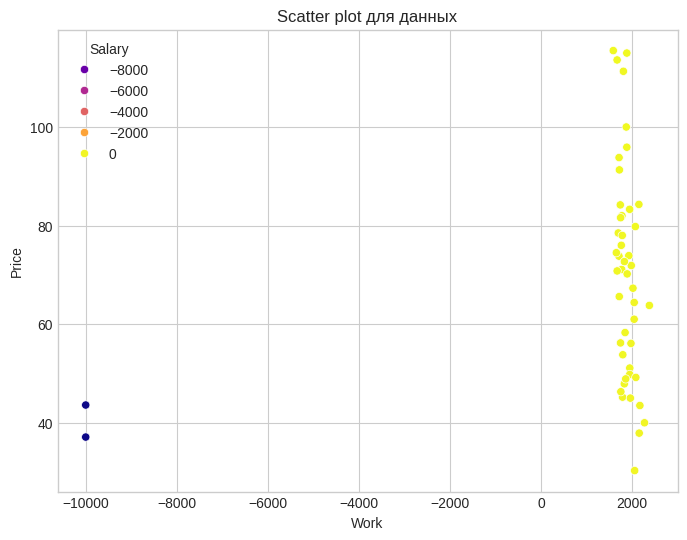

In [6]:
plt.figure(figsize=(8,6))
sns.scatterplot(x = dataset['Work'], y = dataset['Price'], hue = dataset['Salary'], palette='plasma')
plt.title('Scatter plot для данных')
plt.show()

Видим два выброса, это незаполненные данные. Удалим их.

In [7]:
dataset = dataset[dataset['Work']>0]

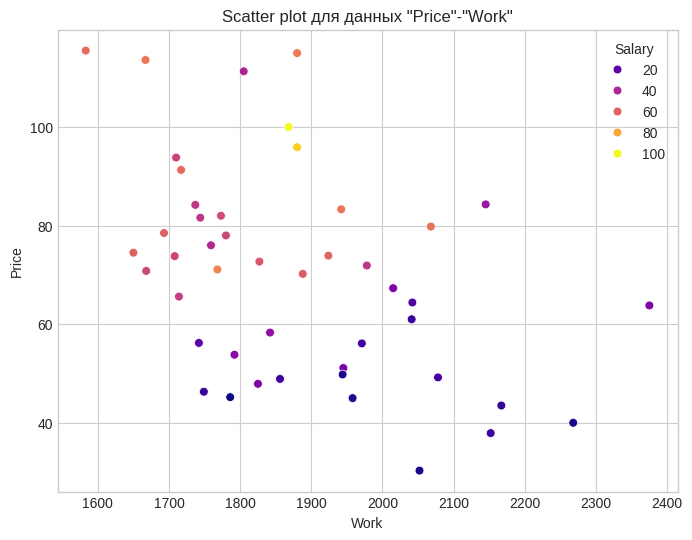

In [8]:
plt.figure(figsize=(8,6))
sns.scatterplot(x = dataset['Work'], y = dataset['Price'], hue = dataset['Salary'], s = 40, palette='plasma')
plt.title('Scatter plot для данных "Price"-"Work"')
plt.show()

Построим scatter plot в 3D.

In [9]:
fig = px.scatter_3d(dataset, x='Work', y='Price', z='Salary', title='3D Scatter Plot')
fig.update_layout(width=1000, height=800)
fig.show()

Изучим масштаб данных.

In [10]:
dataset.describe()

,Work,Price,Salary
count,46.000000,46.000000,46.000000
mean,1879.913043,70.100000,39.545652
std,174.342552,21.389177,24.757703
min,1583.000000,30.300000,2.700000
25%,1745.250000,51.775000,14.375000
50%,1849.000000,70.950000,43.650000
75%,1976.250000,81.900000,59.700000
max,2375.000000,115.500000,100.000000


Заметим, что масштаб величин в колонках разный, следовательно, необходимо стандартизировать. Буду использовать `StandardScaler()`.


> Стандартизация (standardization, z-score normalization) центрирует признак относительно среднего и масштабирует его так, чтобы дисперсия стала равна единице. Формула преобразования:
$$x' = \frac{x - \mu}{\sigma},$$
где $$\mu = \frac{1}{n} \sum_{i=1}^n x_i, \quad \sigma = \sqrt{\frac{1}{n} \sum_{i=1}^n (x_i - \mu)^2}$$
[Стандартизация](http://www.machinelearning.ru/wiki/index.php?title=%D0%9D%D0%BE%D1%80%D0%BC%D0%B0%D0%BB%D0%B8%D0%B7%D0%B0%D1%86%D0%B8%D1%8F_%D0%B8_%D1%81%D1%82%D0%B0%D0%BD%D0%B4%D0%B0%D1%80%D1%82%D0%B8%D0%B7%D0%B0%D1%86%D0%B8%D1%8F_%D0%BF%D1%80%D0%B8%D0%B7%D0%BD%D0%B0%D0%BA%D0%BE%D0%B2)



In [11]:
scaler = StandardScaler()
X = scaler.fit_transform(dataset[['Work','Price','Salary']])
X = pd.DataFrame(X, index=dataset.index, columns=['Work','Price','Salary'])
X.head()

,Work,Price,Salary
0,-0.962166,-0.212712,0.386095
1,-0.509827,-0.770489,-0.373488
2,1.577891,-1.522069,-1.145323
3,0.997969,-1.881316,-1.398517
4,-0.996961,0.174896,0.447351


# Кластеризация методом k-средних

Проводим кластеризацию методом k-средних. Для этого используем `KMeans` модуля библиотеки `sklearn.cluster`.

Алгоритм k-means:
1) Пользователь задает руками k.
2) Алгоритм выбирает начальные точки кластеров - центры кластеров.
3) Для каждой точки вычисляется евклидово расстояние между ней и центрами кластеров.
4) Каждая точка выборки относится к тому центроиду, к которому она ближе всего.
5) Центроиды новых образованных кластеров пересчитываются.
6) Шаги 3-5 повторяются итеративно, пока алгоритм не сойдется.

In [12]:
#  максимальное число итераций
max_iter_1 = 300

# инициализация модели
model = KMeans(n_clusters=2, random_state=42, max_iter=max_iter_1, n_init=10,
               verbose=0, tol=0.0001)


In [13]:
model.fit(X)

KMeans(n_clusters=2, n_init=10, random_state=42)

Достаточно ли итераций?

In [14]:
model.n_iter_


3

Определим число кластеров. Для этого построим график зависимости суммы квадрата расстояний от числа кластеров.
Суммарное квадратичное отклонение точек кластеров от центров этих кластеров (суммарная инерция):

$$V = \sum_{i=1}^{k} \sum_{x \in S_i} (x - \mu_i)^2
$$
где $k$ — число кластеров, $S_i$ — полученные кластеры, $i = 1, 2, ..., k$, а $\mu_i$ — центры масс всех векторов $x$ из кластера $S_i$.

Определим, построив график "каменистая осыпь", в какой момент инерция перестает при изменении числа кластеров значительно уменьшаться.

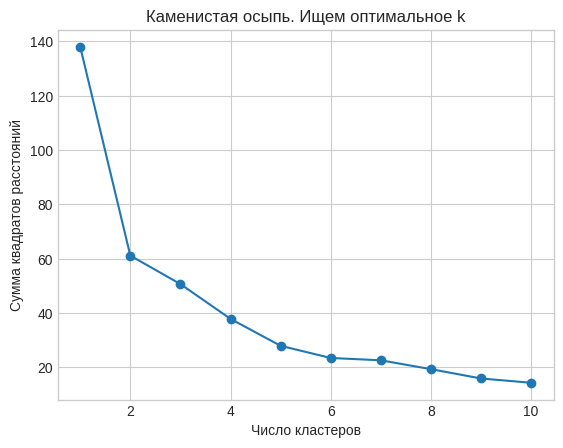

In [15]:
K = range(1, 11)

# Вычисляем значения критерия качества для разного числа кластеров
models = [KMeans(n_clusters=k, random_state=42).fit(X) for k in K]
dist = [model.inertia_ for model in models]

# Строим график каменистая осыпь
plt.plot(K, dist, marker='o')
plt.xlabel('Число кластеров')
plt.ylabel('Сумма квадратов расстояний')
plt.title('Каменистая осыпь. Ищем оптимальное k')
plt.show()

Оптимальное k: $k=2$

In [16]:
#  К таблице данных dataset_k_means добавим столбец cluster,
#  содержащий код того кластера, в который попал объект.
dataset_k_means = dataset.copy()
dataset_k_means['cluster'] = model.labels_+1


In [17]:
dataset_k_means.groupby('cluster').mean(numeric_only=True)

,Work,Price,Salary
cluster,,,
1,1987.857143,52.395238,16.347619
2,1789.240000,84.972000,59.032000


Получили 2 кластера.

**1 кластер**  - страны с низкой зарплатой и большим количеством рабочих часов. Среди них Панама, Гонк-Конг, Манила, Мехико и т.д.

**2 кластер** - развитые города Америки, Европы, Австралии. Среди них Амстердам, Лондон, Мадрид, Нью-Йорк, Париж. Это страны с хорошей зарплатой сопоставимой с стоимостью жизни.

Визуализируем их на `ScatterPlot`:

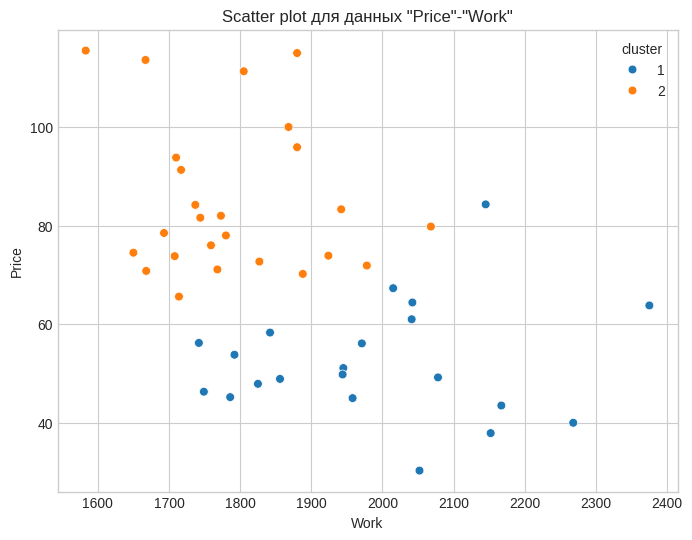

In [19]:
plt.figure(figsize=(8,6))
sns.scatterplot(x = dataset_k_means['Work'], y = dataset_k_means['Price'], hue = dataset_k_means['cluster'], palette = 'tab10', s = 40)
plt.title('Scatter plot для данных "Price"-"Work"')
plt.show()

In [20]:
fig = px.scatter_3d(dataset_k_means, x='Work', y='Price', z='Salary', color='cluster', title='3D Scatter Plot')
fig.update_layout(width=1000, height=800)
fig.show()

In [21]:
dataset_k_means.groupby('cluster').size().to_frame(name='count').rename_axis('cluster')

,count
cluster,
1,21
2,25


In [23]:
for cluster in [0, 1]:
  print(f'cluster: {cluster+1}')
  for el in dataset_k_means[dataset_k_means['cluster']==cluster].index:
    print(dataset.loc[el, 'City'])
  print('')

cluster: 1

cluster: 2
Athens
Bogota
Bombay
Buenos_Aires
Caracas
Hong_Kong
Johannesburg
Kuala_Lumpur
Lagos
Lisbon
Manila
Mexico_City
Nairobi
Nicosia
Panama
Rio_de_Janeiro
San_Paulo
Seoul
Singpore
Taipei
Tel_Aviv



# Метод DBSCAN

Параметры:
1) $\varepsilon$ - радиус шара вокруг точки.
2) `MinPts` - минимальное число точек, которые должны находиться в шаре, чтобы центр шара считать корневой точкой.

Типы точек:
1) Корневые - точки, в $\varepsilon$-окрестности которых не менее  `MinPts` соседей.
2) Граничные - точки, не являющиеся корневыми, но находящиеся в $\varepsilon$-окрестности хотя бы одной точки.
3) Выбросы - ни корневые, ни граничные точки.

Алгоритм:
1) Пользователь задает $\varepsilon$ и `MinPts`.
2) Выбирается корневая точка, ей присваевается кластер, и все соседи точки из $\varepsilon$-окрестности записываются в кластер. Процедура повторяется рекурсивно со всеми корневыми точками из получившегося кластера.
3) Из оставшихся точек выбирается корневая точка, ей присваивается второй кластер, повторяется пункт 2 в новом кластере.
4) Оставшиеся точки, не причисленные ни к одному кластеру, считаются фоном или выбросами, и все записываются в единый кластер.

In [25]:
dataset_dbscan = dataset.copy()

#начинаю с значений по умолчанию
dbscan_1 = DBSCAN()
dbscan_1.fit(X)

DBSCAN()

In [26]:
dbscan_1.labels_

array([ 0, -1, -1, -1,  0, -1, -1, -1, -1,  0,  0, -1, -1, -1, -1, -1, -1,
       -1, -1, -1,  0, -1, -1, -1, -1, -1,  0,  0, -1, -1, -1, -1, -1,  0,
       -1, -1, -1, -1, -1,  0, -1, -1, -1, -1,  0, -1])

In [30]:
table = pd.Series(dbscan_1.labels_).value_counts()
table.sort_index(inplace=True)

print(table)

-1    36
 0    10
Name: count, dtype: int64


36 выбросов - очень много. Пробую менять параметры.

In [46]:
dbscan_2 = DBSCAN(eps = 2, metric = 'euclidean',min_samples = 2)
dbscan_2.fit(X)

table = pd.Series(dbscan_2.labels_).value_counts()
table.sort_index(inplace=True)

print(table)

0    46
Name: count, dtype: int64


Получили один кластер - не годится. Увеличу  `min_samples` и уменьшу $\varepsilon$.

In [44]:
dbscan_3 = DBSCAN(eps = 1.5, metric = 'euclidean',min_samples = 5)
dbscan_3.fit(X)

table = pd.Series(dbscan_3.labels_).value_counts()
table.sort_index(inplace=True)

print(table)

-1     1
 0    45
Name: count, dtype: int64


Не получается подобрать параметры. Попробую искать максимальный `silhouette` на моделях `DBSCAN` с различными параметрами.

Метрику `Silhoutte` $s(i)$ можно вычислить по формуле:

$$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))},$$

где $a(i)$ - среднее расстояние от точки
$i$ до всех остальных точек её же кластера, $b(i)$ -  среднее расстояние от точки $i$ до всех точек ближайшего соседнего кластера.

$s(i) \in [-1;1].$

In [50]:
eps = np.arange(0.5,3,0.1)
min_samples = np.arange(2,15,1)
n_clusters = 0
max_value = [0, 0, 0, -1]
sil = []

for i in range(len(eps)):
    for j in range(len(min_samples)):

        db = DBSCAN(min_samples = min_samples[j], eps =eps[i]).fit(X)

        labels = db.labels_

        # Число кластеров, после отбрасывания выбросов.
        if -1 in labels:
          n_clusters = len(set(labels)) - 1
        else:
          n_clusters = len(set(labels))

        if n_clusters > 1:
            silhouette = metrics.silhouette_score(X, labels)
            if silhouette > max_value[3]:
                max_value=(eps[i], min_samples[j], n_clusters, silhouette)
            sil.append(silhouette)

print("epsilon=", max_value[0],
      "\nmin_sample=", max_value[1],
      "\nnumber of clusters=", max_value[2],
      "\naverage silhouette score= %.4f" % max_value[3])

epsilon= 0.7999999999999999 
min_sample= 2 
number of clusters= 4 
average silhouette score= 0.3935


In [66]:
dbscan_leader = DBSCAN(eps = 0.8, metric = 'euclidean',min_samples = 2)
dbscan_leader.fit(X)

table = pd.Series(dbscan_leader.labels_).value_counts()
table.sort_index(inplace=True)

print(table)

-1     4
 0    19
 1    19
 2     2
 3     2
Name: count, dtype: int64


Получили 4 кластера + 4 выброса.

In [72]:
#  К таблице данных dataset_dbscan добавим столбец cluster,
#  содержащий код того кластера, в который попал объект.
dataset_dbscan['cluster'] = dbscan_leader.labels_+1


In [76]:
dataset_dbscan.groupby('cluster').mean(numeric_only=True)

,Work,Price,Salary
cluster,,,
0,2051.250000,93.600000,42.375000
1,1792.000000,77.526316,55.157895
2,1959.210526,50.115789,14.789474
3,1874.000000,97.950000,95.150000
4,1625.000000,114.550000,65.150000


In [78]:
for cluster in [0, 1, 2, 3, 4]:
  print(f'cluster: {cluster+1}')
  for el in dataset_dbscan[dataset_dbscan['cluster']==cluster].index:
    print(dataset.loc[el, 'City'])
  print('')

cluster: 1
Hong_Kong
Stockholm
Taipei
Tokyo

cluster: 2
Amsterdam
Brussels
Chicago
Copenhagen
Dublin
Dusseldorf
Frankfurt
Houston
London
Los_Angeles
Luxembourg
Madrid
Milan
Montreal
New_York
Paris
Sydney
Toronto
Vienna

cluster: 3
Athens
Bogota
Bombay
Buenos_Aires
Caracas
Johannesburg
Kuala_Lumpur
Lagos
Lisbon
Manila
Mexico_City
Nairobi
Nicosia
Panama
Rio_de_Janeiro
San_Paulo
Seoul
Singpore
Tel_Aviv

cluster: 4
Geneva
Zurich

cluster: 5
Helsinki
Oslo



Получили 4 кластера.

**0 кластер** - Выбросы.

**1 кластер** - города с зарплатой, близкой к стоимости жизни: Милан, Мадрид, Дублин, Амстердам и т.д. Число рабочих часов менее, чем в 1 кластере.

**2 кластер** - города с зарплатой, которая сильно ниже средних цен: Куала-Лумпур, Каракас, Панама и др. Количество рабочих часов в этих странах велико.

**3 кластер** - "Премиум" города: Женева, Цюрих. Средняя зарплата сравнима с стоимостью жизни.

**4 кластер** - "Дорогая" Европа: Хельсинки, Осло. Страны с небольшим количеством рабочих часов, высокой стоимостью жизни.




Визуализируем их на `ScatterPlot`:

In [67]:
fig = px.scatter_3d(dataset_dbscan, x='Work', y='Price', z='Salary', color='cluster', title='3D Scatter Plot')
fig.update_layout(width=1000, height=800)
fig.show()

In [79]:
dataset_dbscan.groupby('cluster').size().to_frame(name='count').rename_axis('cluster')

,count
cluster,
0,4
1,19
2,19
3,2
4,2


**Вывод:**

В ходе работы была проведена кластеризация городов методом k-средних и методом DBSCAN. Данные были очищены от выбросов, а также стандартизированы.

В ходе кластеризации методом k-means, исследуя график зависимости суммарной инерции от количества кластеров, удалось выделить 2 кластера:

* Кластер 1 - страны с низкой зарплатой и большим количеством рабочих часов. Среди них Панама, Гонк-Конг, Манила, Мехико и т.д.

* Кластер 2 - развитые города Америки, Европы, Австралии. Среди них Амстердам, Лондон, Мадрид, Нью-Йорк, Париж. Это страны с хорошей зарплатой сопоставимой с стоимостью жизни.

В ходе кластеризации методом DBSCAN, мксимизируя метрику `Silhouette`, удалось подобрать оптимальные параметры и выделить 4 кластера,  также 4 выброса:

* Кластер 1 - города с зарплатой, близкой к стоимости жизни ("Развитая Европа"): Милан, Мадрид, Дублин, Амстердам и т.д. Число рабочих часов менее, чем в 1 кластере.

* Кластер 2 - города с зарплатой, которая сильно ниже средних цен: Куала-Лумпур, Каракас, Панама и др. Количество рабочих часов в этих странах велико.

* Кластер 3 - "Премиум" города: Женева, Цюрих. Средняя зарплата сравнима с стоимостью жизни.

* Кластер 4 - "Дорогая" Европа: Хельсинки, Осло. Страны с небольшим количеством рабочих часов, высокой стоимостью жизни.

В итоге можно сделать вывод, что K-means смог разбить выборку на глобальные подвыборки, в то время как DBSCAN выявил тонкие особенности, а также отделил выбросы.